# RNN Practice

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("All libraries imported successfully!")

c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.4) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Pandas: 3.0.6
NumPy: 2.4.6
Matplotlib: 3.11.1
Scikit-learn: 1.9.0
TensorFlow: 2.21.0
All libraries imported successfully!


In [2]:
import pandas as pd

file_path = r"C:\Users\Dell\RNN-deepleaning\data\rnn_daily_weather_practice.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (730, 4)


,date,temperature_c,humidity_percent,rainfall_mm
0,2024-01-01,23.03,72.0,0.0
1,2024-01-02,21.71,70.0,0.0
2,2024-01-03,24.38,72.4,0.0
3,2024-01-04,24.29,68.7,0.0
4,2024-01-05,19.65,71.0,0.0


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nBasic Statistics:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              730 non-null    str    
 1   temperature_c     730 non-null    float64
 2   humidity_percent  730 non-null    float64
 3   rainfall_mm       730 non-null    float64
dtypes: float64(3), str(1)
memory usage: 30.1 KB

Missing Values:
date                0
temperature_c       0
humidity_percent    0
rainfall_mm         0
dtype: int64

Duplicate Rows:
0

Basic Statistics:


,temperature_c,humidity_percent,rainfall_mm
count,730.000000,730.000000,730.000000
mean,27.938479,58.072055,1.929644
std,4.148729,10.207685,5.104778
min,19.150000,31.600000,0.000000
25%,24.400000,50.025000,0.000000
50%,27.880000,57.700000,0.000000
75%,31.565000,66.300000,0.000000
max,36.960000,84.000000,45.270000


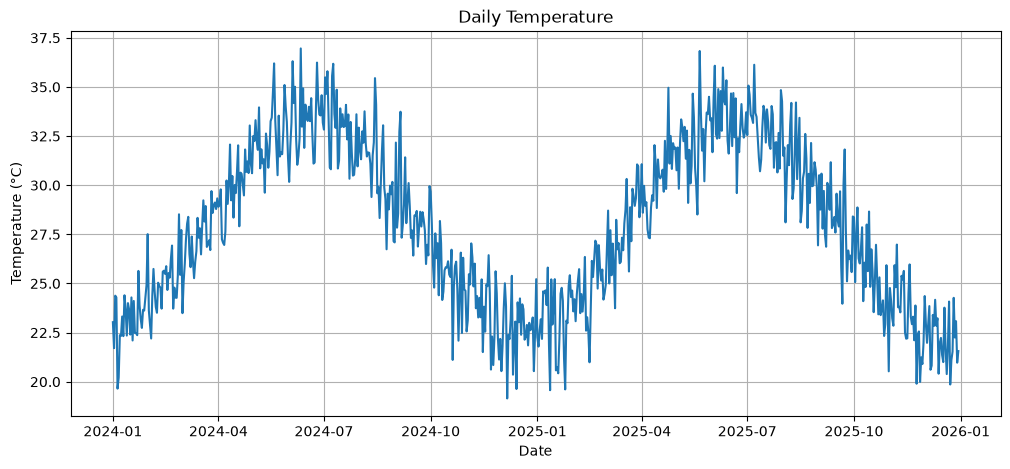

In [4]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Sort data by date
df = df.sort_values("date").reset_index(drop=True)

# Plot temperature over time
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["temperature_c"])

plt.title("Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

In [5]:
# Select temperature column
temperature_data = df[["temperature_c"]].copy()

print("Temperature data shape:", temperature_data.shape)
temperature_data.head()

Temperature data shape: (730, 1)


,temperature_c
0,23.03
1,21.71
2,24.38
3,24.29
4,19.65


In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_temperature = scaler.fit_transform(temperature_data)

print("Original temperature:")
print(temperature_data.head())

print("\nScaled temperature:")
print(scaled_temperature[:5])

Original temperature:
   temperature_c
0          23.03
1          21.71
2          24.38
3          24.29
4          19.65

Scaled temperature:
[[0.21785514]
 [0.14373947]
 [0.29365525]
 [0.28860191]
 [0.02807412]]


In [7]:
import numpy as np

LOOKBACK = 7

X = []
y = []

for i in range(LOOKBACK, len(scaled_temperature)):
    X.append(scaled_temperature[i - LOOKBACK:i, 0])
    y.append(scaled_temperature[i, 0])

X = np.array(X)
y = np.array(y)

# RNN input shape: samples, time steps, features
X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (723, 7, 1)
y shape: (723,)


In [8]:
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Training samples: 578
Testing samples: 145
X_train shape: (578, 7, 1)
X_test shape: (145, 7, 1)


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

tf.random.set_seed(42)

model = Sequential([
    SimpleRNN(32, activation="tanh", input_shape=(LOOKBACK, 1)),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0883 - mae: 0.2599 - val_loss: 0.0563 - val_mae: 0.2232
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0160 - mae: 0.0999 - val_loss: 0.0171 - val_mae: 0.1136
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0114 - mae: 0.0833 - val_loss: 0.0114 - val_mae: 0.0912
Epoch 4/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0100 - mae: 0.0786 - val_loss: 0.0091 - val_mae: 0.0812
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0099 - mae: 0.0788 - val_loss: 0.0082 - val_mae: 0.0766
Epoch 6/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0100 - mae: 0.0795 - val_loss: 0.0082 - val_mae: 0.0770
Epoch 7/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0101 - mae: 0.0797 - val_loss: 0.0083 - val_mae: 0.0772
Epoch 8/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0100 - mae: 0.0797 - val_loss: 0.0083 - val_mae: 0.0775
Epoch 9/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0100 - mae:

In [10]:
# Predict temperatures using test data
y_pred_scaled = model.predict(X_test)

print("Predictions completed!")
print("Predictions shape:", y_pred_scaled.shape)

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step
Predictions completed!
Predictions shape: (145, 1)


In [11]:
# Convert scaled values back to Celsius
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

print("Actual temperatures (°C):")
print(y_test_actual[:5].flatten())

print("\nPredicted temperatures (°C):")
print(y_pred_actual[:5].flatten())

Actual temperatures (°C):
[34.19 29.3  29.84 31.81 34.21]

Predicted temperatures (°C):
[30.825304 31.981766 29.7565   29.638845 31.286394]


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print(f"MAE: {mae:.2f} °C")
print(f"RMSE: {rmse:.2f} °C")

MAE: 1.47 °C
RMSE: 1.76 °C


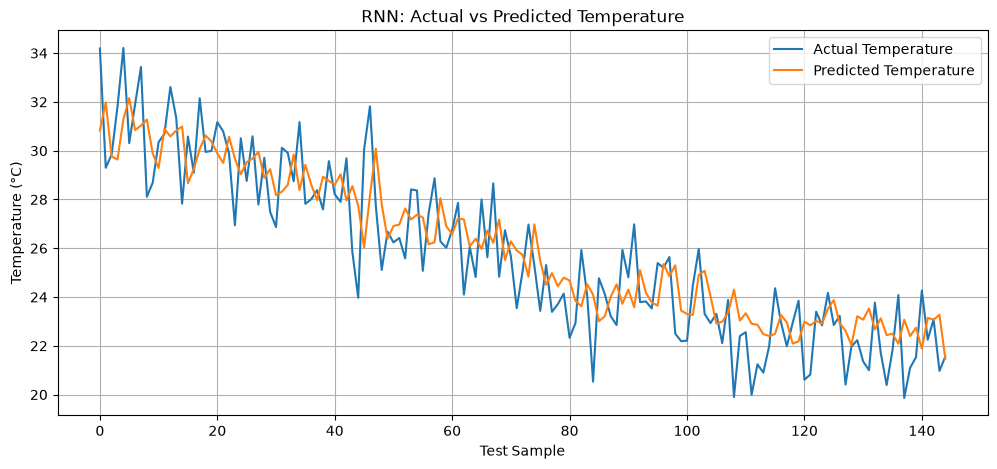

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_actual, label="Actual Temperature")
plt.plot(y_pred_actual, label="Predicted Temperature")

plt.title("RNN: Actual vs Predicted Temperature")
plt.xlabel("Test Sample")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Take the latest 7 days of temperature data
last_7_days = scaled_temperature[-LOOKBACK:]

# RNN expects: (samples, time steps, features)
next_input = last_7_days.reshape(1, LOOKBACK, 1)

# Predict the next day's temperature
next_temp_scaled = model.predict(next_input, verbose=0)

# Convert prediction back to Celsius
next_temp_celsius = scaler.inverse_transform(next_temp_scaled)[0, 0]

print(f"Predicted next-day temperature: {next_temp_celsius:.2f} °C")

Predicted next-day temperature: 22.60 °C


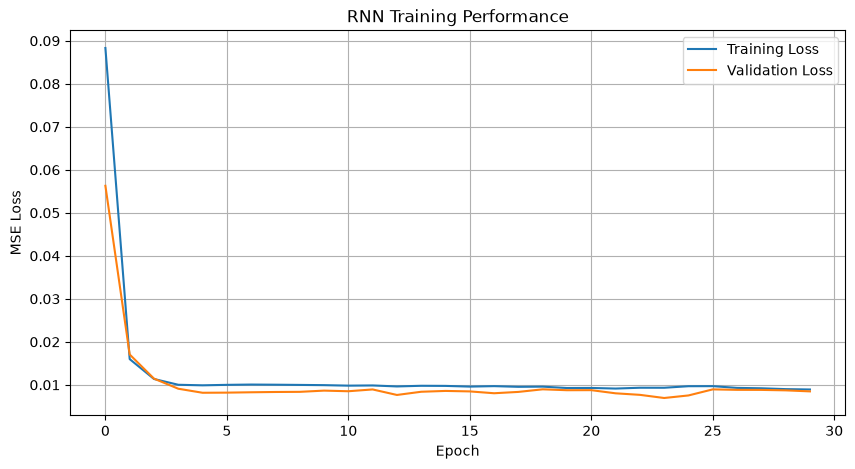

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("RNN Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
results = pd.DataFrame({
    "Actual_Temperature": y_test_actual.flatten(),
    "Predicted_Temperature": y_pred_actual.flatten()
})

results["Absolute_Error"] = abs(
    results["Actual_Temperature"] - results["Predicted_Temperature"]
)

results.head(10)

,Actual_Temperature,Predicted_Temperature,Absolute_Error
0,34.19,30.825304,3.364696
1,29.30,31.981766,2.681766
2,29.84,29.756500,0.083500
3,31.81,29.638845,2.171155
4,34.21,31.286394,2.923606
5,30.31,32.153114,1.843114
6,31.91,30.843941,1.066059
7,33.43,31.028795,2.401205
8,28.11,31.273666,3.163666
9,28.69,29.885548,1.195548


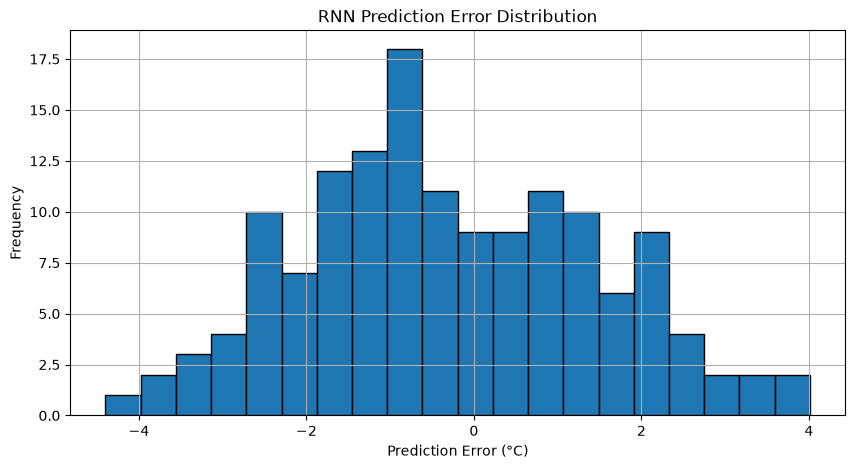

In [17]:
errors = (
    y_test_actual.flatten() -
    y_pred_actual.flatten()
)

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=20, edgecolor="black")

plt.title("RNN Prediction Error Distribution")
plt.xlabel("Prediction Error (°C)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [18]:
import os

os.makedirs("models", exist_ok=True)

model.save("models/rnn_temperature_model.keras")

print("RNN model saved successfully!")

RNN model saved successfully!


In [19]:
import joblib

joblib.dump(
    scaler,
    "models/temperature_scaler.pkl"
)

print("Temperature scaler saved successfully!")

Temperature scaler saved successfully!


In [20]:
from tensorflow.keras.models import load_model
import joblib
import numpy as np

loaded_model = load_model("models/rnn_temperature_model.keras")
loaded_scaler = joblib.load("models/temperature_scaler.pkl")

print("RNN model loaded successfully!")
print("Scaler loaded successfully!")

RNN model loaded successfully!
Scaler loaded successfully!


In [21]:
# Latest 7 days of temperature
last_7_days = temperature_data["temperature_c"].values[-LOOKBACK:]

# Scale using the saved scaler
last_7_days_scaled = loaded_scaler.transform(
    last_7_days.reshape(-1, 1)
)

# Prepare RNN input
new_input = last_7_days_scaled.reshape(1, LOOKBACK, 1)

# Predict next-day temperature
prediction_scaled = loaded_model.predict(new_input, verbose=0)

# Convert to Celsius
prediction_celsius = loaded_scaler.inverse_transform(
    prediction_scaled
)[0, 0]

print(f"Next-day predicted temperature: {prediction_celsius:.2f} °C")

c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Next-day predicted temperature: 22.60 °C
